# Filament coils
This example designs modular coils for li383 with QUADCOIL. The example contains 
three problems:

1. An unconstrained NESCOIL problem. It produces windowpane coils (2.1).
2. A topology constrained problem that removes windowpanes (2.2).
3. A curvature minimizing problem (3).

It also shows how to cut QUADCOIL solutions into filament coils (4).

## 1. Loading data

In [1]:
from quadcoil import quadcoil
from quadcoil.quantities import K_theta, Phi_with_net_current
from quadcoil.io import simsopt_coil_from_qp

import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

from simsopt import load
from simsopt.geo import curves_to_vtk
from simsopt.field import BiotSavart
from simsopt.objectives import SquaredFlux

jax.config.update('jax_enable_x64', True)

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


In [2]:
# The example is li383.
_, plasma_surface = load('data/surfaces.json')
net_poloidal_current_amperes = 11884578.094260072

# Number of poloidal and toroidal harmonics in the current potential,
# shared by every run in this notebook.
MPOL_NTOR = 8

# Arguments common to every QUADCOIL call. The winding surface is
# auto-generated at one minor radius from the plasma.
problem_kwargs = dict(
    nfp=plasma_surface.nfp,
    stellsym=plasma_surface.stellsym,
    mpol=MPOL_NTOR,
    ntor=MPOL_NTOR,
    plasma_dofs=plasma_surface.get_dofs(),
    plasma_mpol=plasma_surface.mpol,
    plasma_ntor=plasma_surface.ntor,
    net_poloidal_current_amperes=net_poloidal_current_amperes,
    net_toroidal_current_amperes=0.,
    plasma_coil_distance=plasma_surface.minor_radius(),
)
# Field error, current magnitude and the coil curvature proxy.
metrics = ('f_B', 'f_K', 'f_max_K_dot_grad_K_cyl')

## 2. Optimizing modular coils
Modular coils are contours of the current potential $\Phi$ that wrap the
torus poloidally. This requires the poloidal sheet current $K_\theta$ to have
the same sign as the net poloidal current everywhere on the winding surface.

In [3]:
if net_poloidal_current_amperes > 0:
    K_theta_sign = '>='
else:
    K_theta_sign = '<='
print('K_theta should be', K_theta_sign, '0')

K_theta should be >= 0


### 2.1. Running NESCOIL

In [4]:
out_dict_nescoil, qp_nescoil, dofs_nescoil, _ = quadcoil(
    **problem_kwargs,
    objective_name='f_B',
    metric_name=metrics,
)
print('f_B of NESCOIL:        ', out_dict_nescoil['f_B']['value'])
print('Minimum K_theta of NESCOIL:', jnp.min(K_theta(qp_nescoil, dofs_nescoil)))

f_B of NESCOIL:         0.0064049430463666325
Minimum K_theta of NESCOIL: -1474161250.5279417


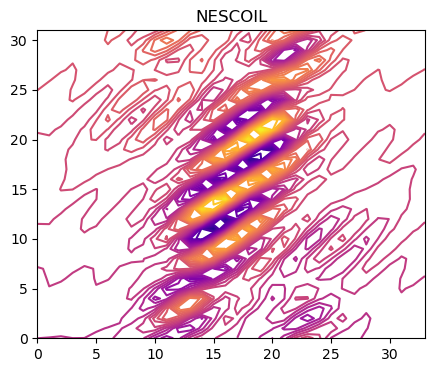

In [5]:
plt.figure(figsize=(5, 4))
plt.title('NESCOIL')
plt.contour(Phi_with_net_current(qp_nescoil, dofs_nescoil), levels=40, cmap='plasma')
plt.show()

NESCOIL only minimizes the field error, so $K_\theta$ changes sign on parts of
the winding surface. There, contours of $\Phi$ close on themselves instead of
wrapping poloidally. These closed contours are windowpane coils, which are
undesirable for a modular coil set.

### 2.2. Running with the topology constraint
$K_\theta\geq0$ is a pointwise constraint over the whole winding surface.
We use `smoothing='slack'`, which enforces it exactly with slack variables.
The default `smoothing='approx'` replaces it with a smooth log-sum-exp
approximation intended for quasi-single-stage optimization, which does not
enforce it tightly enough to remove windowpane coils at this resolution.

In [6]:
out_dict_topo, qp_topo, dofs_topo, status_topo = quadcoil(
    **problem_kwargs,
    objective_name='f_B',
    constraint_name=('K_theta',),
    constraint_type=(K_theta_sign,),
    constraint_value=np.array([0.]),
    constraint_unit=(None,),
    metric_name=metrics,
    smoothing='slack',
)
print('f_B with K_theta constraint:    ', out_dict_topo['f_B']['value'])
print('f_B without constraint:         ', out_dict_nescoil['f_B']['value'])
print('Minimum K_theta with constraint:', jnp.min(K_theta(qp_topo, dofs_topo)))
print('Max K dot grad K (cylindrical): ', out_dict_topo['f_max_K_dot_grad_K_cyl']['value'])

f_B with K_theta constraint:     0.04107817756548254
f_B without constraint:          0.0064049430463666325
Minimum K_theta with constraint: -236.1773320119828
Max K dot grad K (cylindrical):  308398681937173.06


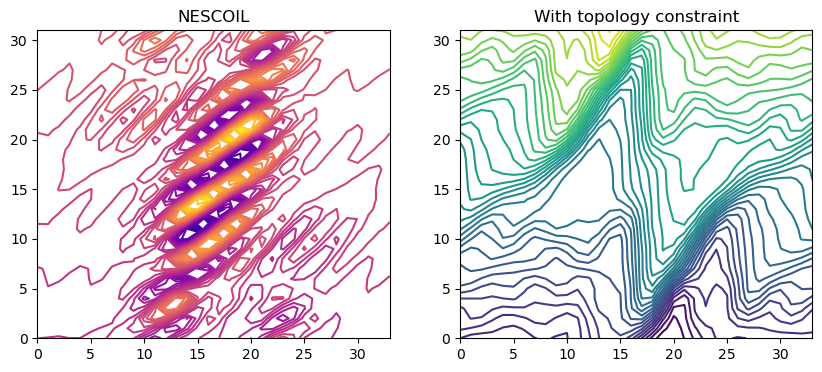

In [7]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.title('NESCOIL')
plt.contour(Phi_with_net_current(qp_nescoil, dofs_nescoil), levels=40, cmap='plasma')
plt.subplot(1, 2, 2)
plt.title('With topology constraint')
plt.contour(Phi_with_net_current(qp_topo, dofs_topo), levels=40)
plt.show()

## 3. Filament optimization
The coils are cut along contours of $\Phi$, so their curvature is governed by
$K\cdot\nabla K$. Here, we keep the topology constraint and a fixed field error,
and minimize
$$\max_{WS}\|K\cdot\nabla K\|_\infty.$$

We allow the field error to be twice that of section 2.2. For reference, we
also run REGCOIL (minimizing $f_K$) at the same field error. Because QUADCOIL
does constrained optimization, REGCOIL can target a desired $f_B$ directly
instead of sweeping the regularization parameter.

In [8]:
f_B_target = 2 * out_dict_topo['f_B']['value']
f_K_ref = out_dict_topo['f_K']['value']

out_dict_regcoil, qp_regcoil, dofs_regcoil, _ = quadcoil(
    **problem_kwargs,
    objective_name='f_K',
    objective_unit=f_K_ref,
    constraint_name=('f_B',),
    constraint_type=('<=',),
    constraint_value=np.array([f_B_target]),
    constraint_unit=(f_B_target,),
    metric_name=metrics,
    smoothing='slack',
)
f_max_K_dot_grad_K_cyl_ref = out_dict_regcoil['f_max_K_dot_grad_K_cyl']['value']
print('f_B of REGCOIL:', out_dict_regcoil['f_B']['value'])
print('Target f_B:    ', f_B_target)
print('Max K dot grad K (cylindrical) of REGCOIL:', f_max_K_dot_grad_K_cyl_ref)

f_B of REGCOIL: 0.08215637039608305
Target f_B:     0.08215635513096509
Max K dot grad K (cylindrical) of REGCOIL: 77180231326125.66


In [9]:
%%time
# The first constraint is the topology constraint. The second makes
# sure this case has the same f_B as the REGCOIL case.
out_dict_curv, qp_curv, dofs_curv, status_curv = quadcoil(
    **problem_kwargs,
    objective_name='f_max_K_dot_grad_K_cyl',
    objective_unit=f_max_K_dot_grad_K_cyl_ref,
    constraint_name=('K_theta', 'f_B'),
    constraint_type=(K_theta_sign, '<='),
    constraint_value=np.array([0., f_B_target]),
    constraint_unit=(None, f_B_target),
    metric_name=metrics,
    smoothing='slack',
)

CPU times: user 29min 8s, sys: 2.94 s, total: 29min 11s
Wall time: 2min 1s


In [10]:
cases = {
    'Topology (2.2)': (out_dict_topo, qp_topo, dofs_topo),
    'REGCOIL': (out_dict_regcoil, qp_regcoil, dofs_regcoil),
    'Curvature-optimized': (out_dict_curv, qp_curv, dofs_curv),
}
print(f"{'Case':<22}{'f_B':>12}{'min K_theta':>16}{'max K.gradK':>16}")
for name, (out, qp_i, dofs_i) in cases.items():
    print(
        f"{name:<22}"
        f"{float(out['f_B']['value']):>12.4e}"
        f"{float(jnp.min(K_theta(qp_i, dofs_i))):>16.4e}"
        f"{float(out['f_max_K_dot_grad_K_cyl']['value']):>16.4e}"
    )
ratio = (
    out_dict_curv['f_max_K_dot_grad_K_cyl']['value']
    / out_dict_topo['f_max_K_dot_grad_K_cyl']['value']
)
print(f'Curvature-optimized max K.gradK is {float(ratio):.3f}x that of section 2.2.')

Case                           f_B     min K_theta     max K.gradK
Topology (2.2)          4.1078e-02     -2.3618e+02      3.0840e+14
REGCOIL                 8.2156e-02     -1.9799e+06      7.7180e+13
Curvature-optimized     3.9772e-02      4.5770e+01      2.8517e+14
Curvature-optimized max K.gradK is 0.925x that of section 2.2.


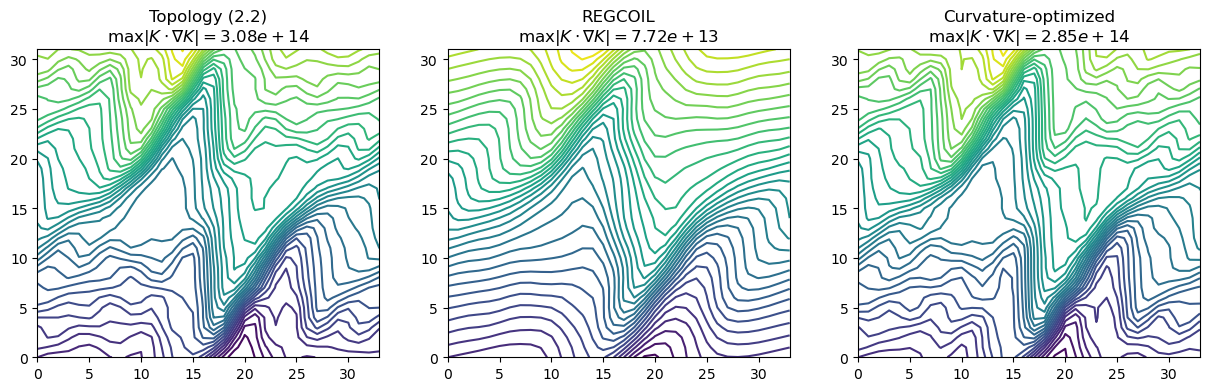

In [11]:
plt.figure(figsize=(15, 4))
for i, (name, (out, qp_i, dofs_i)) in enumerate(cases.items()):
    plt.subplot(1, 3, i + 1)
    kgk = float(out['f_max_K_dot_grad_K_cyl']['value'])
    plt.title(name + '\n' + rf'$\max|K\cdot\nabla K| = {kgk:.2e}$')
    plt.contour(Phi_with_net_current(qp_i, dofs_i), levels=40)
plt.show()

## 4. Cutting and converting to simsopt coils
We cut both the topology-constrained and the curvature-optimized current
potentials into filament coils, save them to VTK, and compare the squared flux
of the filaments with the winding-surface $f_B$.

Cutting complete. Number of coils/half field period: 5
[topology] Squared flux from filament coils: 0.053147734826609824
[topology] Squared flux from winding surface: 0.04107817756548254
Cutting complete. Number of coils/half field period: 5
[curvature] Squared flux from filament coils: 0.05101114301974195
[curvature] Squared flux from winding surface: 0.03977170917725687


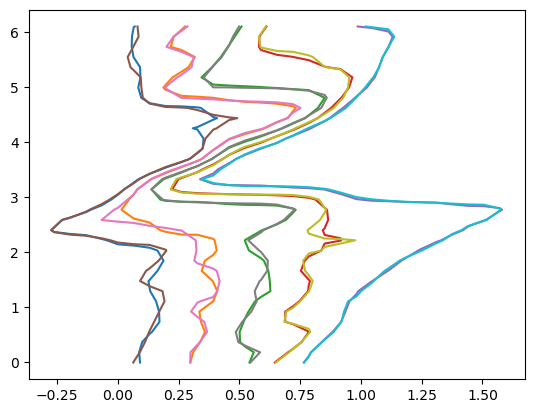

In [12]:
filament_coils = {}
for name, out, qp_i, dofs_i in [
    ('topology', out_dict_topo, qp_topo, dofs_topo),
    ('curvature', out_dict_curv, qp_curv, dofs_curv),
]:
    coils = simsopt_coil_from_qp(
        qp=qp_i,
        dofs=dofs_i,
        coils_per_half_period=5,
        theta_shift=0,
        order=10,
        ppp=40,
    )
    curves_to_vtk([c.curve for c in coils], f'coils_{name}')
    Jf = SquaredFlux(qp_i.plasma_surface.to_simsopt(), BiotSavart(coils))
    filament_coils[name] = coils
    print(f'[{name}] Squared flux from filament coils:', Jf.J())
    print(f'[{name}] Squared flux from winding surface:', out['f_B']['value'])

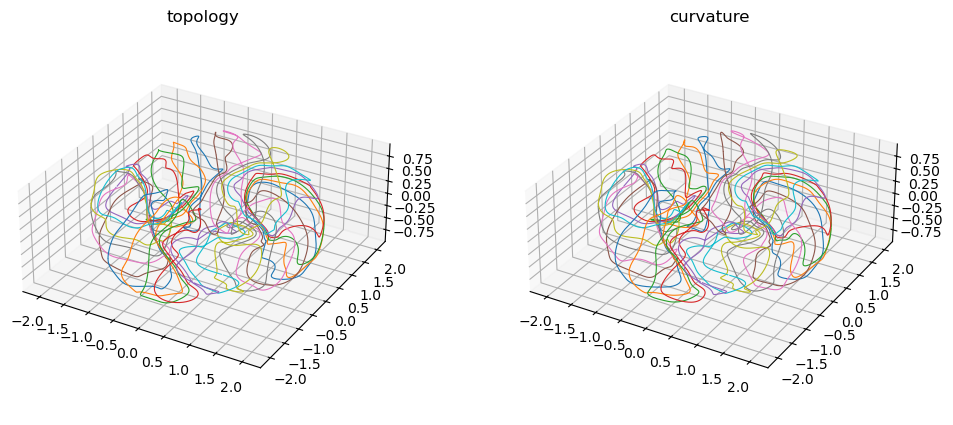

In [13]:
fig = plt.figure(figsize=(12, 5))
for i, (name, coils) in enumerate(filament_coils.items()):
    ax = fig.add_subplot(1, 2, i + 1, projection='3d')
    ax.set_title(name)
    for c in coils:
        g = c.curve.gamma()
        ax.plot(g[:, 0], g[:, 1], g[:, 2], lw=0.8)
    ax.set_aspect('equal')
plt.show()